In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Circuit 1: 0 occurs more often  (H, T, H = 3 gates)
qc_zero = QuantumCircuit(1, 1)   # starts in |0>
qc_zero.h(0)
qc_zero.t(0)
qc_zero.h(0)
qc_zero.measure(0, 0)

# Circuit 2: 1 occurs more often  (X, H, T, H = 4 gates)
qc_one = QuantumCircuit(1, 1)
qc_one.x(0)
qc_one.h(0)
qc_one.t(0)
qc_one.h(0)
qc_one.measure(0, 0)

print("Circuit 1: more 0s"); print(qc_zero.draw())
print("Circuit 2: more 1s"); print(qc_one.draw())

Circuit 1: more 0s
     ┌───┐┌───┐┌───┐┌─┐
  q: ┤ H ├┤ T ├┤ H ├┤M├
     └───┘└───┘└───┘└╥┘
c: 1/════════════════╩═
                     0 
Circuit 2: more 1s
     ┌───┐┌───┐┌───┐┌───┐┌─┐
  q: ┤ X ├┤ H ├┤ T ├┤ H ├┤M├
     └───┘└───┘└───┘└───┘└╥┘
c: 1/═════════════════════╩═
                          0 


In [2]:
print("PREDICTIONS (before running)")
print("-" * 55)
print("Circuit 1 (H, T, H):")
print("  0 will occur more often: about 85% '0' and 15% '1'.\n")
print("Circuit 2 (X, H, T, H):")
print("  1 will occur more often: about 85% '1' and 15% '0'.\n")
print("If I change the gates, the percentages change.")
print("The T gate shifts the phase, and the second H turns that phase")
print("difference into unequal 0/1 probabilities.")

PREDICTIONS (before running)
-------------------------------------------------------
Circuit 1 (H, T, H):
  0 will occur more often: about 85% '0' and 15% '1'.

Circuit 2 (X, H, T, H):
  1 will occur more often: about 85% '1' and 15% '0'.

If I change the gates, the percentages change.
The T gate shifts the phase, and the second H turns that phase
difference into unequal 0/1 probabilities.


In [3]:
sim = AerSimulator()
shots = 100

def run_circuit(qc):
    compiled = transpile(qc, sim)
    result = sim.run(compiled, shots=shots).result()
    return result.get_counts()

counts_zero = run_circuit(qc_zero)
counts_one = run_circuit(qc_one)

print("Circuit 1 results:", counts_zero)
print("Circuit 2 results:", counts_one)

Circuit 1 results: {'0': 87, '1': 13}
Circuit 2 results: {'1': 77, '0': 23}


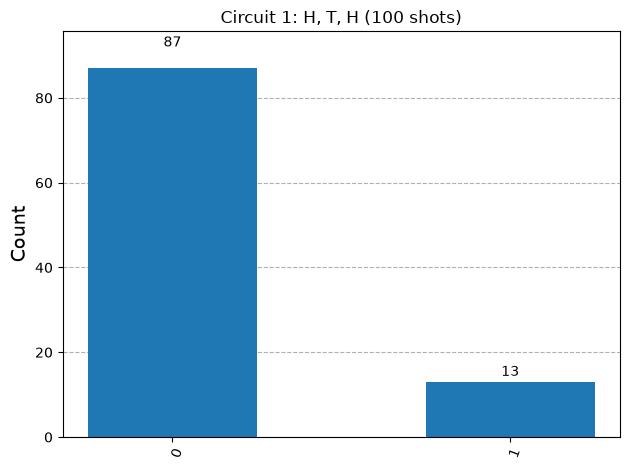

In [4]:
plot_histogram(counts_zero, title="Circuit 1: H, T, H (100 shots)")

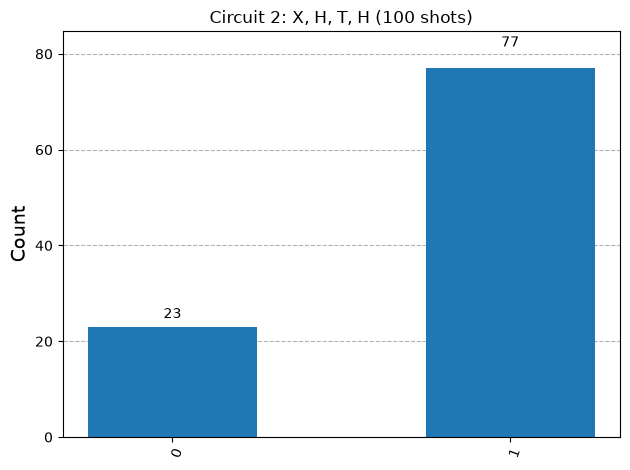

In [5]:
plot_histogram(counts_one, title="Circuit 2: X, H, T, H (100 shots)")

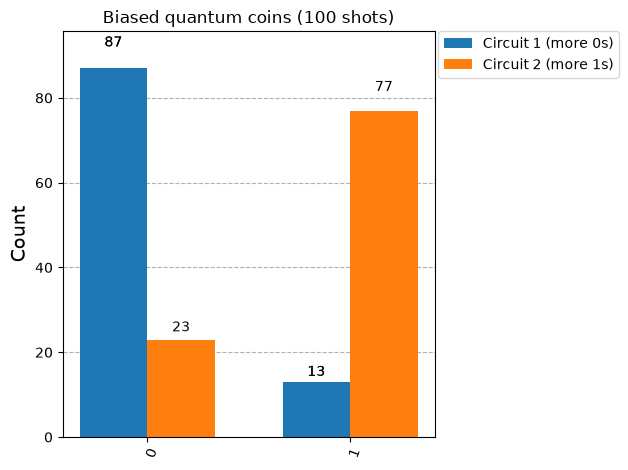

In [6]:
plot_histogram([counts_zero, counts_one],
               legend=["Circuit 1 (more 0s)", "Circuit 2 (more 1s)"],
               title="Biased quantum coins (100 shots)")

ry(pi/6) {'0': 92, '1': 8}
ry(pi/3) {'0': 78, '1': 22}
ry(pi/2) {'0': 48, '1': 52}
ry(2pi/3) {'1': 71, '0': 29}


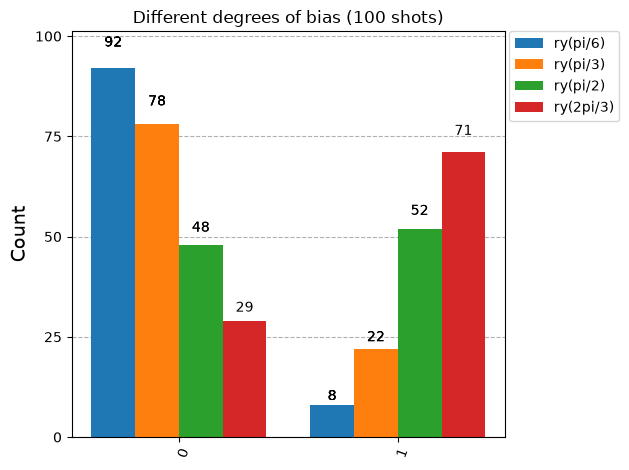

In [7]:
from math import pi

angles = {"ry(pi/6)": pi/6, "ry(pi/3)": pi/3, "ry(pi/2)": pi/2, "ry(2pi/3)": 2*pi/3}
all_counts, labels = [], []

for name, theta in angles.items():
    qc = QuantumCircuit(1, 1)
    qc.ry(theta, 0)
    qc.measure(0, 0)
    c = run_circuit(qc)
    all_counts.append(c)
    labels.append(name)
    print(name, c)

plot_histogram(all_counts, legend=labels, title="Different degrees of bias (100 shots)")

In [8]:
print("COMPARISON: PREDICTIONS vs ACTUAL RESULTS")
print("-" * 60)
print(f"Circuit 1 (H,T,H)   | Predicted: ~85% '0', ~15% '1' | Actual: {counts_zero}")
print(f"Circuit 2 (X,H,T,H) | Predicted: ~15% '0', ~85% '1' | Actual: {counts_one}")

print("\nHow the gates changed the distribution:")
print("H alone gives a 50/50 coin. Adding a T gate between two H gates adds a phase")
print("to the |1> part of the superposition. The second H makes the two parts")
print("interfere, so the outcomes are no longer equal. H, T, H gives about 85% '0'.")
print("Adding an X gate at the start swaps the result, giving about 85% '1'.")

COMPARISON: PREDICTIONS vs ACTUAL RESULTS
------------------------------------------------------------
Circuit 1 (H,T,H)   | Predicted: ~85% '0', ~15% '1' | Actual: {'0': 87, '1': 13}
Circuit 2 (X,H,T,H) | Predicted: ~15% '0', ~85% '1' | Actual: {'1': 77, '0': 23}

How the gates changed the distribution:
H alone gives a 50/50 coin. Adding a T gate between two H gates adds a phase
to the |1> part of the superposition. The second H makes the two parts
interfere, so the outcomes are no longer equal. H, T, H gives about 85% '0'.
Adding an X gate at the start swaps the result, giving about 85% '1'.


In [9]:
print("CHALLENGE QUESTION")
print("How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?\n")
print("ANSWER:")
print("A qubit's state is a combination of |0> and |1>, each with an amplitude.")
print("The probability of measuring 0 or 1 is the square of the size of its amplitude.")
print("Quantum gates change these amplitudes. The X gate swaps them, so 0 becomes 1.")
print("The H gate splits the state into an equal superposition, giving 50/50 odds.")
print("Phase gates like T do not change the probabilities directly, but when followed")
print("by another H gate, the amplitudes interfere and the probabilities become unequal.")
print("Rotation gates like Ry change the amplitudes directly, so any bias can be chosen.")
print("So by choosing and ordering gates, we control the probability of measuring 0 or 1.")

CHALLENGE QUESTION
How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?

ANSWER:
A qubit's state is a combination of |0> and |1>, each with an amplitude.
The probability of measuring 0 or 1 is the square of the size of its amplitude.
Quantum gates change these amplitudes. The X gate swaps them, so 0 becomes 1.
The H gate splits the state into an equal superposition, giving 50/50 odds.
Phase gates like T do not change the probabilities directly, but when followed
by another H gate, the amplitudes interfere and the probabilities become unequal.
Rotation gates like Ry change the amplitudes directly, so any bias can be chosen.
So by choosing and ordering gates, we control the probability of measuring 0 or 1.
